In [2]:
from google.colab import files

uploaded = files.upload()

Saving archive (3).zip to archive (3).zip


In [3]:

import zipfile
import os
import glob
import pandas as pd

zip_path = next(
    (f for f in glob.glob("/content/*.zip")),
    None
)

if zip_path is None:
    raise FileNotFoundError("Please upload archive.zip first.")

extract_path = "/content/instagram_data"
os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_path)

files_found = glob.glob(
    extract_path + "/**/*", recursive=True
)

print("Extracted files:")
for f in files_found:
    if os.path.isfile(f):
        print(f)


Extracted files:
/content/instagram_data/follows.csv
/content/instagram_data/photos.csv
/content/instagram_data/photo_tags.csv
/content/instagram_data/comments.csv
/content/instagram_data/users.csv
/content/instagram_data/tags.csv
/content/instagram_data/likes.csv


In [5]:

csv_files = glob.glob(
    extract_path + "/**/*.csv", recursive=True
)

excel_files = (
    glob.glob(extract_path + "/**/*.xlsx", recursive=True)
    + glob.glob(extract_path + "/**/*.xls", recursive=True)
)

if csv_files:
    data_path = csv_files[0]
    df = pd.read_csv(data_path)
elif excel_files:
    data_path = excel_files[0]
    df = pd.read_excel(data_path)
else:
    raise FileNotFoundError(
        "No CSV or Excel file found in the ZIP."
    )

print("Loaded file:", data_path)
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nFirst five rows:")
display(df.head())


Loaded file: /content/instagram_data/follows.csv
Dataset shape: (7623, 5)

Column names:
['follower', 'followee ', 'created time', 'is follower active', 'followee Acc status']

First five rows:


,follower,followee,created time,is follower active,followee Acc status
0,2,1,13-04-2023 08:04,1,Private
1,2,3,13-04-2023 08:04,0,private
2,2,4,13-04-2023 08:04,0,public
3,2,5,13-04-2023 08:04,0,private
4,2,6,13-04-2023 08:04,1,private


In [6]:
import os

for root, dirs, files in os.walk("/content/instagram_data"):
    for file in files:
        print(file)

follows.csv
photos.csv
photo_tags.csv
comments.csv
users.csv
tags.csv
likes.csv


In [7]:

import pandas as pd
import os

base_path = "/content/instagram_data"

users = pd.read_csv(os.path.join(base_path, "users.csv"))
photos = pd.read_csv(os.path.join(base_path, "photos.csv"))
photo_tags = pd.read_csv(os.path.join(base_path, "photo_tags.csv"))
comments = pd.read_csv(os.path.join(base_path, "comments.csv"))
likes = pd.read_csv(os.path.join(base_path, "likes.csv"))
tags = pd.read_csv(os.path.join(base_path, "tags.csv"))
follows = pd.read_csv(os.path.join(base_path, "follows.csv"))

datasets = {
    "users": users,
    "photos": photos,
    "photo_tags": photo_tags,
    "comments": comments,
    "likes": likes,
    "tags": tags,
    "follows": follows
}

for name, data in datasets.items():
    print(f"\n{name}: {data.shape}")
    print(data.columns.tolist())



users: (100, 6)
['id', 'name', 'created time', 'private/public', 'post count', 'Verified status']

photos: (257, 6)
['id', 'image link', 'user ID', 'created dat', 'Insta filter used', 'photo type']

photo_tags: (501, 3)
['photo', 'tag ID', 'user id']

comments: (7488, 8)
['id', 'comment', 'User  id', 'Photo id', 'created Timestamp', 'posted date', 'emoji used', 'Hashtags used count']

likes: (8782, 5)
['user ', 'photo', 'created time', 'following or not', 'like type']

tags: (21, 4)
['id', 'tag text', 'created time', 'location']

follows: (7623, 5)
['follower', 'followee ', 'created time', 'is follower active', 'followee Acc status']


In [8]:

display(photos.head())
display(likes.head())
display(comments.head())
display(tags.head())
display(users.head())


,id,image link,user ID,created dat,Insta filter used,photo type
0,1,http://elijah.biz,1,13-04-2023 08:04,yes,photo
1,2,https://shanon.org,1,13-04-2023 08:04,no,photo
2,3,http://vicky.biz,1,13-04-2023 08:04,no,photo
3,4,http://oleta.net,1,13-04-2023 08:04,no,photo
4,5,https://jennings.biz,1,13-04-2023 08:04,yes,photo


,user,photo,created time,following or not,like type
0,2,1,13-04-2023 08:04,yes,heart emoji
1,2,4,13-04-2023 08:04,no,thumbs up
2,2,8,13-04-2023 08:04,yes,laughing
3,2,9,13-04-2023 08:04,no,fire
4,2,10,13-04-2023 08:04,yes,clap


,id,comment,User id,Photo id,created Timestamp,posted date,emoji used,Hashtags used count
0,1,unde at dolorem,2,1,13-04-2023 08:04,April 14,yes,1
1,2,quae ea ducimus,3,1,13-04-2023 08:04,April 14,no,2
2,3,alias a voluptatum,5,1,13-04-2023 08:04,April 14,no,4
3,4,facere suscipit sunt,14,1,13-04-2023 08:04,April 14,yes,2
4,5,totam eligendi quaerat,17,1,13-04-2023 08:04,April 14,yes,1


,id,tag text,created time,location
0,1,sunset,13-04-2023 08:04,florida
1,2,photography,13-04-2023 08:04,washington DC
2,3,sunrise,13-04-2023 08:04,new york
3,4,landscape,13-04-2023 08:04,london
4,5,food,13-04-2023 08:04,brazil


,id,name,created time,private/public,post count,Verified status
0,1,Kenton_Kirlin,16-02-2017 18:22,yes,11,no
1,2,Andre_Purdy85,02-04-2017 17:11,no,7,no
2,3,Harley_Lind18,21-02-2017 11:12,no,2,no
3,4,Arely_Bogan63,13-08-2016 01:28,yes,1,no
4,5,Aniya_Hackett,07-12-2016 01:04,yes,3,no


In [9]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Standardize column names
for data in datasets.values():
    data.columns = data.columns.str.strip()

photos = photos.drop_duplicates(subset="id").copy()
likes = likes.drop_duplicates().copy()
comments = comments.drop_duplicates(subset="id").copy()
tags = tags.drop_duplicates(subset="id").copy()

# Parse dates
photos["created dat"] = pd.to_datetime(
    photos["created dat"], errors="coerce", dayfirst=True
)
likes["created time"] = pd.to_datetime(
    likes["created time"], errors="coerce", dayfirst=True
)
comments["posted date"] = pd.to_datetime(
    comments["posted date"], errors="coerce", dayfirst=True
)
follows["created time"] = pd.to_datetime(
    follows["created time"], errors="coerce", dayfirst=True
)

# Engagement per photo
like_counts = likes.groupby("photo").size().rename("likes")
comment_counts = comments.groupby("Photo id").size().rename("comments")

analysis = photos.merge(
    like_counts, left_on="id", right_index=True, how="left"
).merge(
    comment_counts, left_on="id", right_index=True, how="left"
)

analysis[["likes", "comments"]] = analysis[
    ["likes", "comments"]
].fillna(0)

analysis["engagement"] = analysis["likes"] + analysis["comments"]

# Add account follower counts from follow relationships
follower_counts = follows.groupby("followee").size().rename("followers")
analysis = analysis.merge(
    follower_counts, left_on="user ID", right_index=True, how="left"
)
analysis["followers"] = analysis["followers"].fillna(0)

analysis["engagement_per_follower_pct"] = np.where(
    analysis["followers"] > 0,
    analysis["engagement"] / analysis["followers"] * 100,
    np.nan
)

print("Photos analyzed:", len(analysis))
print("Average likes:", round(analysis["likes"].mean(), 2))
print("Average comments:", round(analysis["comments"].mean(), 2))
print("Average total engagement:", round(analysis["engagement"].mean(), 2))
display(analysis.head())


Photos analyzed: 257
Average likes: 34.17
Average comments: 29.14
Average total engagement: 63.31


,id,image link,user ID,created dat,Insta filter used,photo type,likes,comments,engagement,followers,engagement_per_follower_pct
0,1,http://elijah.biz,1,2023-04-13 08:04:00,yes,photo,25,25,50,77,64.935065
1,2,https://shanon.org,1,2023-04-13 08:04:00,no,photo,36,31,67,77,87.012987
2,3,http://vicky.biz,1,2023-04-13 08:04:00,no,photo,38,27,65,77,84.415584
3,4,http://oleta.net,1,2023-04-13 08:04:00,no,photo,38,32,70,77,90.909091
4,5,https://jennings.biz,1,2023-04-13 08:04:00,yes,photo,31,27,58,77,75.324675


,posts,avg_likes,avg_comments,avg_engagement
day,,,,
Monday,NaN,NaN,NaN,NaN
Tuesday,NaN,NaN,NaN,NaN
Wednesday,NaN,NaN,NaN,NaN
Thursday,257.0,34.17,29.14,63.31
Friday,NaN,NaN,NaN,NaN
Saturday,NaN,NaN,NaN,NaN
Sunday,NaN,NaN,NaN,NaN


,posts,avg_engagement
hour,,
8,257,63.31


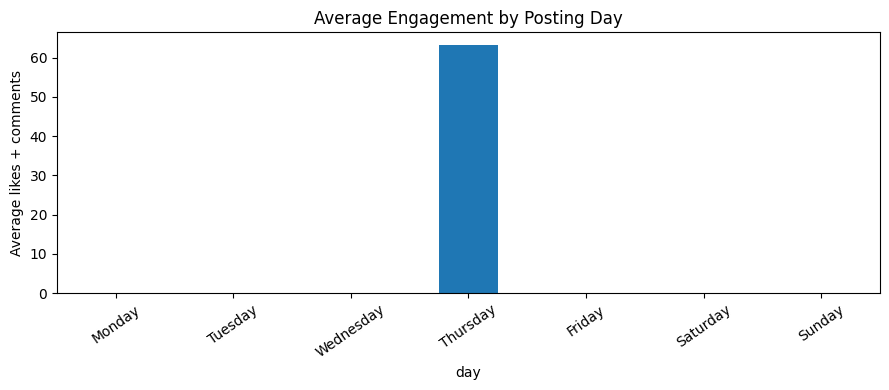

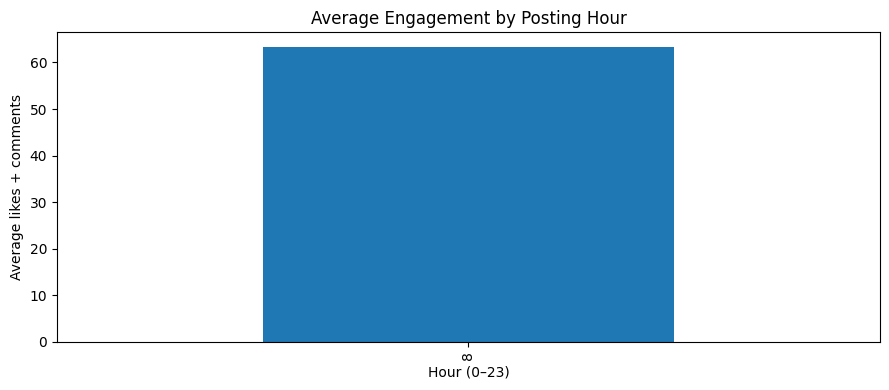

In [10]:

analysis["day"] = analysis["created dat"].dt.day_name()
analysis["hour"] = analysis["created dat"].dt.hour

day_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

day_results = (
    analysis.dropna(subset=["day"])
    .groupby("day")
    .agg(posts=("id", "count"),
         avg_likes=("likes", "mean"),
         avg_comments=("comments", "mean"),
         avg_engagement=("engagement", "mean"))
    .reindex(day_order)
)

hour_results = (
    analysis.dropna(subset=["hour"])
    .groupby("hour")
    .agg(posts=("id", "count"),
         avg_engagement=("engagement", "mean"))
)

display(day_results.round(2))
display(hour_results.round(2))

day_results["avg_engagement"].plot(kind="bar", figsize=(9, 4))
plt.title("Average Engagement by Posting Day")
plt.ylabel("Average likes + comments")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

hour_results["avg_engagement"].plot(kind="bar", figsize=(9, 4))
plt.title("Average Engagement by Posting Hour")
plt.ylabel("Average likes + comments")
plt.xlabel("Hour (0–23)")
plt.tight_layout()
plt.show()


,posts,avg_likes,avg_comments,avg_engagement
photo type,,,,
photo,155,34.39,29.25,63.63
video,52,33.83,29.25,63.08
carousel,50,33.86,28.68,62.54


Hashtags with the highest average engagement:


,posts,avg_engagement,avg_likes,avg_comments
tag text,,,,
delicious,15,65.27,34.93,30.33
beauty,20,65.15,34.95,30.20
foodie,11,64.64,34.73,29.91
sunset,19,64.42,34.21,30.21
stunning,16,64.25,34.94,29.31
food,24,64.12,33.83,30.29
photography,16,64.00,34.50,29.50
dreamy,20,63.90,35.75,28.15
smile,59,63.69,34.46,29.24


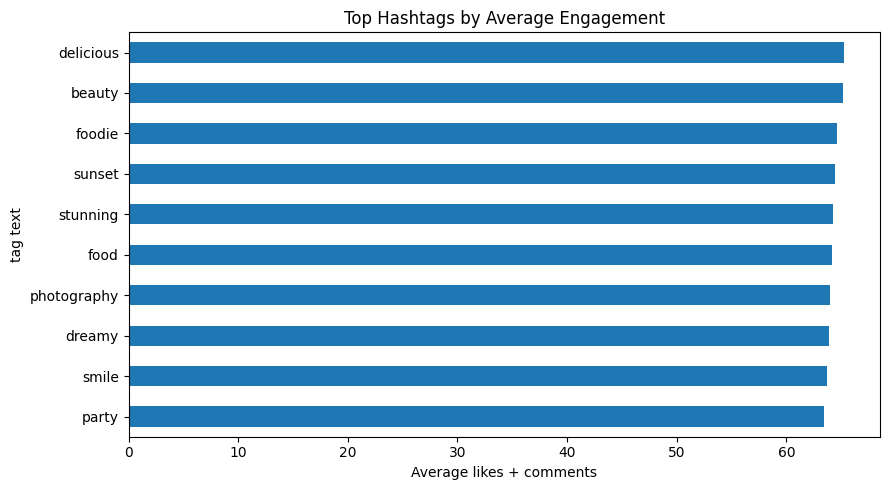

In [11]:

# Compare available photo types
if "photo type" in analysis.columns:
    type_results = (
        analysis.groupby("photo type")
        .agg(posts=("id", "count"),
             avg_likes=("likes", "mean"),
             avg_comments=("comments", "mean"),
             avg_engagement=("engagement", "mean"))
        .sort_values("avg_engagement", ascending=False)
    )
    display(type_results.round(2))

# Map hashtag names to photos
tag_map = photo_tags.merge(
    tags[["id", "tag text"]],
    left_on="tag ID", right_on="id", how="left"
)

hashtag_results = (
    tag_map.merge(
        analysis[["id", "likes", "comments", "engagement"]],
        left_on="photo", right_on="id", how="left"
    )
    .groupby("tag text")
    .agg(posts=("photo", "nunique"),
         avg_engagement=("engagement", "mean"),
         avg_likes=("likes", "mean"),
         avg_comments=("comments", "mean"))
    .sort_values("avg_engagement", ascending=False)
)

print("Hashtags with the highest average engagement:")
display(hashtag_results.head(10).round(2))

hashtag_results.head(10)["avg_engagement"].sort_values().plot(
    kind="barh", figsize=(9, 5)
)
plt.title("Top Hashtags by Average Engagement")
plt.xlabel("Average likes + comments")
plt.tight_layout()
plt.show()


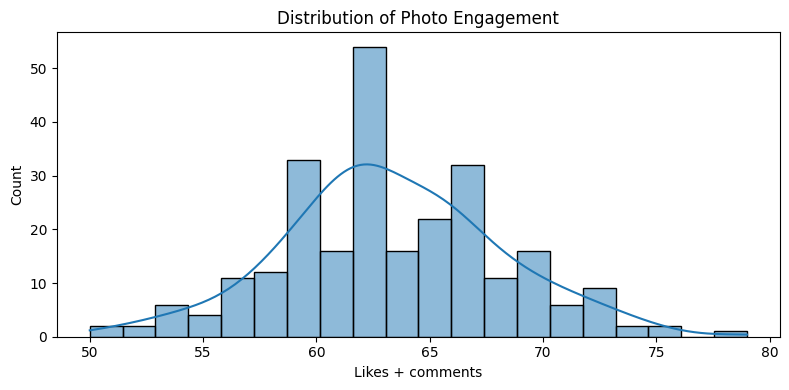

/usr/local/lib/python3.13/dist-packages/pandas/plotting/_matplotlib/core.py:1567: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  ax.set_xlim(left, right)


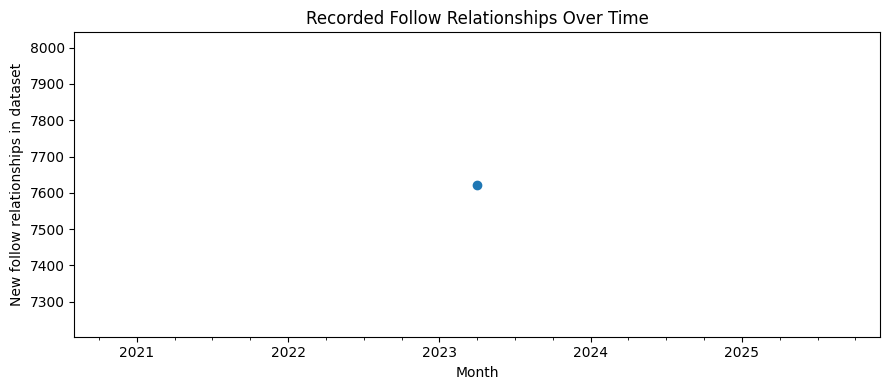

Follower relationship records: 7623
Unique accounts in users file: 100
Unique photos: 257


In [12]:

plt.figure(figsize=(8, 4))
sns.histplot(analysis["engagement"], bins=20, kde=True)
plt.title("Distribution of Photo Engagement")
plt.xlabel("Likes + comments")
plt.tight_layout()
plt.show()

# Followers gained over time in this dataset
follow_growth = (
    follows.dropna(subset=["created time"])
    .set_index("created time")
    .resample("MS")
    .size()
)

follow_growth.plot(kind="line", marker="o", figsize=(9, 4))
plt.title("Recorded Follow Relationships Over Time")
plt.ylabel("New follow relationships in dataset")
plt.xlabel("Month")
plt.tight_layout()
plt.show()

print("Follower relationship records:", len(follows))
print("Unique accounts in users file:", users["id"].nunique())
print("Unique photos:", photos["id"].nunique())


In [13]:

print("INSTAGRAM ANALYSIS SUMMARY")
print("-" * 35)

valid_days = day_results.dropna(subset=["avg_engagement"])
if not valid_days.empty:
    print("Best observed day:",
          valid_days["avg_engagement"].idxmax())

valid_hours = hour_results.dropna(subset=["avg_engagement"])
if not valid_hours.empty:
    print("Best observed hour:",
          int(valid_hours["avg_engagement"].idxmax()))

if "type_results" in globals() and not type_results.empty:
    print("Best observed photo type:",
          type_results["avg_engagement"].idxmax())

if not hashtag_results.empty:
    print("Highest average engagement hashtag:",
          hashtag_results.index[0])

print("\nAverage likes:", round(analysis["likes"].mean(), 2))
print("Average comments:", round(analysis["comments"].mean(), 2))
print("Average engagement:", round(analysis["engagement"].mean(), 2))

print("\nInterpretation:")
print("These findings describe this dataset, not guaranteed future performance.")
print("Follower relationships are not the same as verified follower-growth history.")
print("Test recommended posting times with Alfido Tech's own Instagram Insights.")


INSTAGRAM ANALYSIS SUMMARY
-----------------------------------
Best observed day: Thursday
Best observed hour: 8
Best observed photo type: photo
Highest average engagement hashtag: delicious

Average likes: 34.17
Average comments: 29.14
Average engagement: 63.31

Interpretation:
These findings describe this dataset, not guaranteed future performance.
Follower relationships are not the same as verified follower-growth history.
Test recommended posting times with Alfido Tech's own Instagram Insights.
